In [1]:
import warnings
import pickle
import time
import numpy as np
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import random
import pandas as pd

In [2]:
class cell:
    def __init__(self,index,init_clusters,parent,birth,tau):
        '''Initializes cell attributes
        param:: index: cell index
        param:: clusters: count of n-clusters
        param:: x: plasmid trajectory in time 
        param:: t: time stamps for x
        param:: parent: parent cell
        param:: birth: birth time
        return:: None
        '''
        self.index=index
        self.init_clusters=init_clusters
        self.fin_clusters=[]
        self.x = []
        self.t = []
        self.parent = parent
        self.birth = birth
        self.div = birth+tau#+np.random.normal(0,1)

def find_tot_plasmids(y1,y2,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y2[0]+=y2[1]
    y1[1]=y1[0]
    y2[1]=y2[0]
    y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
    y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
    y_tot = y_tot1+y_tot2
    y1[1]=0
    y2[1]=0
    return y1,y2,y_tot1,y_tot2,y_tot 

def pop_check(cells,T):
    b_filter = [x for x in cells if x.t[0] <= T]
    d_filter = [x for x in b_filter if x.t[-1] >T]
    return d_filter

def hazards(y,c_idx,num_reax,N,beta,gamma,sigma,max_size,t_f,y_totp,y_tot): 
    a = np.zeros(num_reax)                                      #reaction hazards 
    v = np.zeros([num_reax,max_size])                           #reaction vectors    
    a[0]= 1 #(k_tr*y_totp)/(1+K*y_tot/(s0*6.022e2*n*V))**n      #not needed since computation of reaction time is different 
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1
    
    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination
                if (int(species_idx[0,i])==int(species_idx[1,i]) and y[int(species_idx[1,i])]>1 ):
                    v[i,int(species_idx[0,i])] = -2
                    v[i,int(np.sum(species_idx[:,i]))] = 1
                elif not(int(species_idx[0,i])==int(species_idx[1,i])):
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                    v[i,int(np.sum(species_idx[:,i]))] = 1
            else:  #plasmid shedding         
                if int(species_idx[0,i]) == 2:   
                    v[i,0] = 2
                    v[i,int(species_idx[0,i])] = -1 
                else:
                    v[i,0] = 1
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[0,i])-1] = 1 
    return a,v

def time_approx(s,xi,y_tot,eps):
    D=k_tr*xi
    V=V0*np.exp(mu*s)
    C=K*y_tot/(s0*6.022e2*n)
    a_prime = (mu*n*D*C/V)*(1+C/V)**(-n-1)
    a = D/(1+C/V)**n 
    return (-a+np.sqrt(a**2-2*a_prime*np.log(eps)))/a_prime

def ssa_vol(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid cluster count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0              #reaction time 
    y_tot1=x0
    y_tot2 = 0
    clust = [y]
    ty = []
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    while t_y<tau:
        #print('########## new reaction')
        ############################### pole 1 ##################################    
        if y_tot1>0:
            dummy = y1[0]                                               
            y1[0] = 1
            c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
            y1[0] = dummy
            N1 = len(c_idx1)                                            #number of non-zero species
            num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
            a1,v1 = hazards(y1,c_idx1,num_reax1,N1,beta,gamma,sigma,max_size,t_y,y_tot1,y_tot)     
        else:
            num_reax1 = 1
            a1 = [0]
            v1 = np.zeros([1,max_size])
        
        ############################### pole 2 ##################################
        if y_tot2>0:
            dummy = y2[0]
            y2[0]=1
            c_idx2 = np.where(y2>0)[0]                                  
            y2[0]=dummy
            N2 = len(c_idx2)
            num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
            a2,v2 = hazards(y2,c_idx2,num_reax2,N2,beta,gamma,sigma,max_size,t_y,y_tot2,y_tot)
            a = np.append(a1,a2,axis=0)
       
        else:
            num_reax2 = 1
            a2 = [0]
            a = np.append(a1,a2,axis=0)
            v2 = np.zeros([1,max_size])
            
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        epsilon=np.random.uniform(0,1,len(a))
        t_j  = np.zeros(num_reax1+num_reax2+2)
        
        for i in range(len(a)):
            if a[i]==0:
                t_j[i] = np.inf
            else:
                if i == 0: #replication in pole 1
                    t_j[i] = time_approx(t_y,y_tot1,y_tot,epsilon[i])
                elif i == num_reax1:  #replication in pole 2
                    t_j[i] = time_approx(t_y,y_tot2,y_tot,epsilon[i])
                else:
                    t_j[i] = -np.log(epsilon[i])/a[i]
        j=np.argmin(t_j)
        
        if (j==num_reax1+num_reax2): #plasmid transfer pole 1 to 2
            y2[0]+=1
            y1[0]-=1
        elif (j==num_reax1+num_reax2+1): #plasmid transfer pole 2 to 1
            y2[0]-=1
            y1[0]+=1
        elif (num_reax1<=j and j<num_reax1+num_reax2):
            y2+=v2[j-num_reax1,:]  
        else:
            y1+=v1[j,:]    
        y1,y2,y_tot1,y_tot2,y_tot = find_tot_plasmids(y1,y2,max_size)
        if (j==0 or j==num_reax1):
            x= np.append(x,y_tot)
            t_x =np.append(t_x,[t_y])
        t_y+=t_j[j]
        ty =np.append(ty,[t_y]) 
        clust = np.vstack((clust,np.append(y1,y2,axis=0)))
    y = np.append(y1,y2,axis=0)
    return y,x,t_x#,clust,ty

def sim_cells(current,beta,gamma,sigma,max_size):
    y0 = current.init_clusters
    y0[1]=y0[0]
    x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
    y0[1]=0 
    if x0>0:
        yy,xx,tt = ssa_vol(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)

    else:
        yy = y0
        xx = np.array([0,0])
        tt = np.array([0,current.div-current.birth])
    return yy,xx,tt

def pop_sim(Q,tau,beta,gamma,sigma,max_size,Nmax,keep):
    cells =[]                  #processed cells
    N=0                        #cell index
    while len(cells)<=Nmax:
        current = Q[0]
        yy,xx,tt = sim_cells(current,beta,gamma,sigma,max_size)
        
        #update current cell
        current.fin_clusters = yy
        current.x = np.append(xx,[xx[-1]])
        current.t = np.append(tt,[tau])+current.birth   
        cells.extend([current])  
        if len(Q)>=keep:
            rem_cells = random.sample(Q[1:],1)  #cells to be removed  
            new_Q = [x for x in Q if x not in rem_cells]
            Q = new_Q.copy()
        Q.remove(current)  #remove current cell from Q
        
        #generate daughter cells  [index,init_clusters,parent,birth,tau]
        daughter1 = cell(N+1,np.append(yy[:max_size],np.zeros(max_size)),current.index,current.t[-1],tau)
        daughter2 = cell(N+2,np.append(yy[max_size:],np.zeros(max_size)),current.index,current.t[-1],tau)
        N+=2
        Q.extend([daughter1,daughter2])  #add daugthers to Q
        Q = sorted(Q, key=lambda x: x.div, reverse=False) #sort Q wrt cell birth time
        
        if len(cells)%100==0:
            print('cells',len(cells),'Q',len(Q))  
    return cells#,Q

##################################################
n =  2.56  #4.84 #2.56 #8.85
s0 = 0.034 #0.06 #0.034 #0.08  
tau = 30             #30-min doubling time
k_tr = 2.17       
K = 15.8/1.26  
mu = np.log(2)/tau
V0 = 1.2
rho = 0.13

x0=25          #number of plasmids in the initial cell
max_size=200   #total number of possible clusters, can be increased to accomodate larger sims

true_beta = 0.015
true_sigma = 0.08
true_gamm = 0.05



In [3]:
warnings.filterwarnings('ignore')
y0 = np.zeros(2*max_size)
y0[0]=x0
c= cell(0,y0,[],0,tau)   #index,clusters,parent,birth
Q=[c]
Nmax = 10000 
keep = 1000  #keep number of living cells
cells = pop_sim(Q,tau,true_beta,true_gamm,true_sigma,max_size,Nmax,keep)

cells 100 Q 101
cells 200 Q 201
cells 300 Q 301
cells 400 Q 401
cells 500 Q 501
cells 600 Q 601
cells 700 Q 701
cells 800 Q 801
cells 900 Q 901
cells 1000 Q 1000
cells 1100 Q 1000
cells 1200 Q 1000
cells 1300 Q 1000
cells 1400 Q 1000
cells 1500 Q 1000
cells 1600 Q 1000
cells 1700 Q 1000
cells 1800 Q 1000
cells 1900 Q 1000
cells 2000 Q 1000
cells 2100 Q 1000
cells 2200 Q 1000
cells 2300 Q 1000
cells 2400 Q 1000
cells 2500 Q 1000
cells 2600 Q 1000
cells 2700 Q 1000
cells 2800 Q 1000
cells 2900 Q 1000
cells 3000 Q 1000
cells 3100 Q 1000
cells 3200 Q 1000
cells 3300 Q 1000
cells 3400 Q 1000
cells 3500 Q 1000
cells 3600 Q 1000
cells 3700 Q 1000
cells 3800 Q 1000
cells 3900 Q 1000
cells 4000 Q 1000
cells 4100 Q 1000
cells 4200 Q 1000
cells 4300 Q 1000
cells 4400 Q 1000
cells 4500 Q 1000
cells 4600 Q 1000
cells 4700 Q 1000
cells 4800 Q 1000
cells 4900 Q 1000
cells 5000 Q 1000
cells 5100 Q 1000
cells 5200 Q 1000
cells 5300 Q 1000
cells 5400 Q 1000
cells 5500 Q 1000
cells 5600 Q 1000
cells 5700

In [4]:
file_name = 'cells.pkl'
with open(file_name, 'wb') as file:
    pickle.dump(cells, file)

In [2]:
data = pd.read_csv("hsu_data.csv").values
hsu_data = np.unique(data[:,1])

################# stamp 420 #################
684
average cluster size 8.48550194931774
population mean 51.127906976744185
population std 5.5099554260945025
inheritance mean 0.1484231220178462
################# stamp 450 #################
687
average cluster size 8.678675400291127
population mean 50.84950495049505
population std 5.656602621739705
inheritance mean 0.1575369121160888


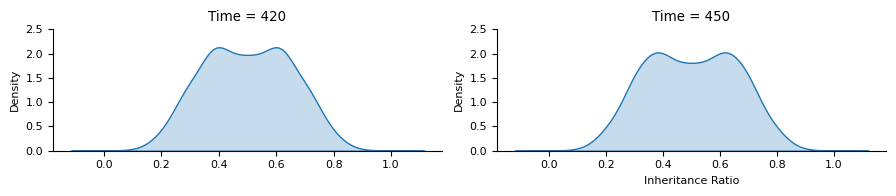

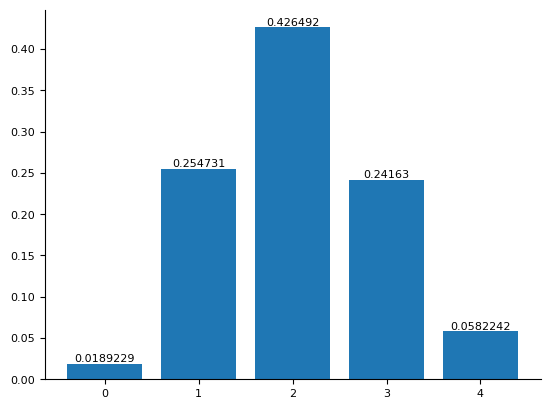

In [55]:
time_stamp = [420,450]
thresh = 5
fig,ax = plt.subplots(1,len(time_stamp),figsize=(9,2))
plt.rc('font', size=8)
ave_cluster = np.zeros(len(time_stamp))
bins = np.linspace(0,1,10)
for j in range(len(time_stamp)):
    print('################# stamp',time_stamp[j],'#################')
    gg = pop_check(cells,time_stamp[j])  ### active cells
    print(len(gg))

    cluster_num = np.zeros_like(gg)
    sum_cluster = 0 
    parents = np.zeros_like(gg)
    for k in range(len(gg)):
        if k>0:
            par = [x for x in cells if x.index == gg[k].parent]  
            parents[k] = par[0].index
        
    u_parent = np.unique(parents[1:])           
    copy = np.zeros_like(u_parent)
    inheritance = np.zeros_like(u_parent)
 
    for k in range(len(u_parent)):
        #print(k)
        cell_i = [x for x in cells if x.parent == u_parent[k]] #find active cells with unique parent
        copy[k]= cell_i[0].x[-1]
        if k>0:            
            par = [x for x in cells if x.index == u_parent[k]] 
            inheritance[k-1] =cell_i[0].x[0]/ par[0].x[-1]                  
   
        ##### distribution of clusters of size at least "threshold" determination
    for k in range(len(gg)):
        yy = gg[k].fin_clusters
        cluster_num[k] = np.sum(yy[thresh:max_size])+np.sum(yy[max_size+thresh:])
        len1 =np.count_nonzero(yy[thresh:max_size])
        len2 =np.count_nonzero(yy[max_size+thresh:])
        if len1+len2>0:
            sum_cluster += np.sum(np.multiply(yy[thresh:max_size],np.arange(thresh,max_size))+np.multiply(yy[max_size+thresh:],np.arange(thresh,max_size)))/(len1+len2)
    #print('ok') 
    ave_cluster[j] = sum_cluster/len(gg)
    height = np.bincount(cluster_num.astype(int))/len(cluster_num)
    dummy=np.sum(height[4:])
    heights=np.zeros(5)
    if len(height)>4:
        height[4]=dummy
        heights = np.delete(height,np.arange(5,len(height)))    
    else:
        heights[:len(height)]=height       
        
    print('average cluster size',ave_cluster[j])
    print('population mean',np.mean(copy))
    print('population std',np.std(copy))
    print('inheritance mean',np.std(inheritance))
    sns.kdeplot(np.append(inheritance,1-inheritance),ax=ax[j],fill=True)
    ax[j].set_ylim([0,2.5])
    ax[j].set_title('Time = %d' %(time_stamp[j]))
ax[1].set_xlabel('Inheritance Ratio')
plt.tight_layout()
sns.despine()

fig, ax = plt.subplots()
ax.bar([0,1,2,3,4],heights)
for bars in ax.containers:
    ax.bar_label(bars)
sns.despine()

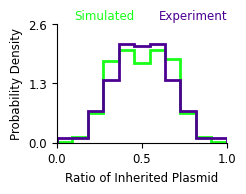

In [90]:
fontsiz=8.5
f=plt.figure(figsize=(2.5,2))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
#col = ["#E1BE6A","#40B0A6"]
col = ["#1AFF1A","#4B0092"]

bins = np.linspace(0,1,12)
ax.hist(np.append(inheritance,1-inheritance),density=True,bins=bins,color=col[0],fill=False,histtype='step',stacked=True,label='Simulated',linewidth=2)
ax.hist(np.append(hsu_data,1-hsu_data),density=True,bins=bins,color=col[1],fill=False,histtype='step',stacked=True,label='Experiment',linewidth=2)
handles1, labels1 = ax.get_legend_handles_labels()
ax.set_xlabel('Ratio of Inherited Plasmid',fontsize=fontsiz)
ax.set_ylabel('Probability Density',fontsize=fontsiz)
ax.tick_params(axis = 'both', which = 'major', labelsize = fontsiz)
ax.set_xlim([0,1])
ax.set_ylim([0,2.5])
plt.xticks([0,0.5,1])
plt.yticks([0,1.3,2.6])

#ax.legend(handles1, labels1, loc='upper center',ncol=2,fontsize=fontsiz,frameon=False,bbox_to_anchor=(0.5, 1.2))
plt.text(0.1,2.7,'Simulated',color=col[0],fontsize=fontsiz)
plt.text(0.6,2.7,'Experiment',color=col[1],fontsize=fontsiz)

plt.tick_params(axis="both", labelsize=fontsiz)
sns.despine()
plt.tight_layout()
plt.savefig("hsu.pdf", format="pdf", bbox_inches="tight")

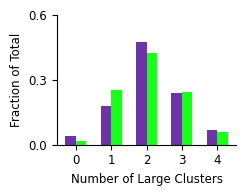

In [84]:
data_cluster = [0.03960396,0.178217822,0.475247525,0.237623762,0.069306931]
width = 0.3 

fontsiz=8.5
f=plt.figure(figsize=(2.5,2))
axes = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42


axes.bar(np.arange(5)+width,heights,width,label='Simulated',color=col[0])
axes.bar(np.arange(5),data_cluster,width,label='Experiment',color=col[1],alpha=0.8)
axes.set_xticks(np.arange(5) + width / 2, np.arange(5))

axes.tick_params(axis = 'both', which = 'major', labelsize = fontsiz)
axes.set_ylabel('Fraction of Total',fontsize=fontsiz)
axes.set_xlabel('Number of Large Clusters',fontsize=fontsiz)
axes.set_yticks([0,0.3,0.6])
handles2, labels2 = axes.get_legend_handles_labels()


#axes.legend(handles2, labels2, loc='upper center',ncol=1,fontsize=fontsiz,frameon=False,bbox_to_anchor=(0.8, 1.1))
sns.despine()
plt.tight_layout()
plt.savefig("yao.pdf", format="pdf", bbox_inches="tight")

# Replication Parameters

Text(0, 0.5, '$s0$')

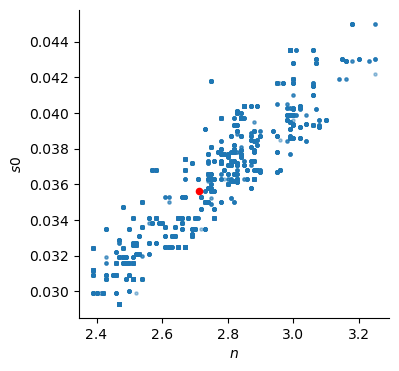

In [10]:
#pd_n_s0 = pd.read_csv('n_s0_fin.csv').values
pd_n_s0 = pd.read_csv('n_s0_fin_new.csv').values
n = pd_n_s0[:,0]
s0 = pd_n_s0[:,1]


burn = 0
vec = np.arange(burn,len(n)-1,5)
n_ = np.mean(n[vec])
s0_ = np.mean(s0[vec])

f = plt.figure(figsize=(4,4))
plt.scatter(n[vec],s0[vec],s=5,alpha=0.4)
plt.scatter([n_],[s0_],color='r',s=20)
sns.despine()
plt.xlabel(r'$n$')
plt.ylabel(r'$s0$')


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.stats import uniform
from numba import jit
import warnings
import pandas as pd
import matplotlib

In [2]:
#@jit
def mnrm(x0,T,s0,V0,mu,n,k_tr,K):
    t_x=0
    x = [x0]
    i=0
    while t_x<T:
        w_t = time_approx(t_x,x[-1],x[-1],np.random.uniform(0,1),s0,V0,mu,n,k_tr,K)
        x=np.append(x,[x[i]+1])
        t_x+=w_t
        i+=1
    return x[-2]

#@jit
def time_approx(s,xi,y_tot,eps,s0,V0,mu,n,k_tr,K):
    D=k_tr*xi
    V=V0*np.exp(mu*s)
    C=K*y_tot/(s0*6.022e2*n)
    a_prime = (mu*n*D*C/V)*(1+C/V)**(-n-1)
    a = D/(1+C/V)**n 
    return (-a+np.sqrt(a**2-2*a_prime*np.log(eps)))/a_prime

In [43]:
warnings.filterwarnings('ignore')

L=10000
n_vec = [2.5,2.75,3]
s0_vec = [0.032, 0.03744748, 0.04109174] 
V0 = 1.2
data = 51
k_tr = 2.17
K = 15.8/1.26
tau =30
x_fin = np.zeros([3,L])
for j in range(3):
    for k in range(L):  
        ################ generate initial conditions #######################
        x0 = -1   
        d_t = np.random.normal(tau,1)
        while x0<0:
            x0 = np.floor(data/2)+(np.random.poisson(1)-np.random.poisson(1))
        x_fin[j,k]= mnrm(x0,d_t,s0_vec[j],V0,np.log(2)/d_t,n_vec[j],k_tr,K)
    print('end of j=%d' %(j))
np.savetxt("x_fin.csv",x_fin, delimiter=",",header=" ")

end of j=0
end of j=1
end of j=2


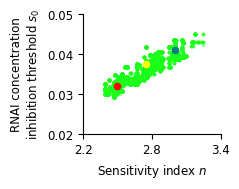

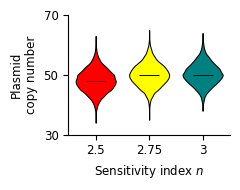

In [48]:
col = ['r','yellow','teal']
fontsiz = 8.5
y = pd.read_csv('y_init1.csv').values

n_s = np.zeros(3)
s0_s = np.zeros(3)

n_s[0] = 2.5
dummy = n.flat[np.abs(n - n_s[0]).argmin()]
s0_s[0] = np.mean(s0[np.where(n == dummy)])

n_s[1] = 2.75
dummy = n.flat[np.abs(n - n_s[1]).argmin()]
s0_s[1] = np.mean(s0[np.where(n == dummy)])

n_s[2] = 3
dummy = n.flat[np.abs(n - n_s[2]).argmin()]
s0_s[2] = np.mean(s0[np.where(n == dummy)])

burn = 0
vec = np.arange(burn, len(n)-1, 5)

# ----------------------------
# Tags
# ----------------------------
tag1 = '2.5'
tag2 = '2.75'
tag3 = '3'
groups = [tag1, tag2, tag3]

# ============================
# FIGURE 1: Scatter plot
# ============================
fig1, ax1 = plt.subplots(figsize=(2.5, 2))
ax1.tick_params(axis='both', which='major', labelsize=fontsiz)

ax1.scatter(n[vec], s0[vec], s=3, alpha=0.3, color="#1AFF1A", zorder=1)

for i in range(3):
    ax1.scatter([n_s[i]], [s0_s[i]], color=col[i], s=20)

ax1.set_xlabel(r'Sensitivity index $n$', fontsize=fontsiz)
ax1.set_ylabel('RNAI concentration\ninhibition threshold $s_0$', fontsize=fontsiz)
ax1.set_ylim([0.02, 0.05])
ax1.set_yticks([0.02, 0.03,0.04, 0.05])
ax1.set_xticks([2.2, 2.8, 3.4])

sns.despine()
fig1.tight_layout()
fig1.savefig("replication_parameters.pdf", format="pdf", bbox_inches="tight")


# ============================
# FIGURE 2: Violin plot
# ============================
fig2, ax2 = plt.subplots(figsize=(2.5, 2))
ax2.tick_params(axis='both', which='major', labelsize=fontsiz)

data_groups = [
    a.loc[a['minutes'] == g, 1].dropna().values
    for g in groups
]

vp = ax2.violinplot(
    data_groups,
    positions=range(len(groups)),
    widths=0.75,
    showmeans=False,
    showmedians=True,
    showextrema=False
)

for body, g in zip(vp['bodies'], groups):
    body.set_facecolor(pal[g])
    body.set_edgecolor('black')
    body.set_linewidth(0.75)
    body.set_alpha(1)

vp['cmedians'].set_color('black')
vp['cmedians'].set_linewidth(0.75)

ax2.set_ylim([30, 70])
ax2.set_ylabel('Plasmid\ncopy number', fontsize=fontsiz)
ax2.set_xlabel('Sensitivity index $n$', fontsize=fontsiz)
ax2.set_yticks([30, 50, 70])
ax2.set_xticks(range(len(groups)))
ax2.set_xticklabels(groups)

sns.despine()
fig2.tight_layout()
fig2.savefig("replication_dist.pdf", format="pdf", bbox_inches="tight")

plt.show()